# TC-ViTok: Model Architecture Deep Dive
## Notebook 2: Architecture

---

This notebook dissects every architectural component of TC-ViTok:
- Three frozen encoders and why each is needed
- The Token Prediction Network (TPN) in detail
- Gumbel-Sigmoid STE: making discrete selection differentiable
- Tau-independent gradient correction
- Informative Token Merge (zero parameters)
- BudgetPredictor for adaptive token counts


In [15]:
import sys, os
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Setup complete")

Setup complete


## 1. Three Frozen Encoders

TC-ViTok uses three pre-trained encoders, all frozen during training.

| Encoder | Input resolution | Output | Purpose |
|---------|-----------------|--------|--------|
| CLIP ViT-L/14 | 336 x 336 px | [B, 576, 1024] -- 24x24 patch tokens | Visual tokens fed to LLM |
| DINOv2-S | 98 x 98 px | [B, 49, 384] -- 7x7 coarse tokens | TPN context features |
| CLIP text encoder | token sequence | [B, 512] | Query embedding for conditioning |

**Why three encoders?**
- **CLIP ViT-L/14** produces the high-resolution tokens that LLaVA-1.5 was trained on. We must use these exact tokens to preserve compatibility with the frozen LLM.
- **DINOv2-S** provides spatial context at low resolution. Its 7x7 grid aligns naturally with the 24x24 CLIP grid (each DINOv2 token covers ~12 CLIP tokens). DINOv2 features are better for spatial localization than CLIP visual features.
- **CLIP text** embeds the question. Using CLIP text ensures the text and visual spaces are aligned (both trained with contrastive CLIP loss), making cross-attention meaningful.


In [16]:
# Illustrate the encoder pipeline shapes
B = 2  # batch size

# Simulated encoder outputs
clip_visual_tokens = torch.randn(B, 576, 1024)  # CLIP ViT-L/14
dino_tokens        = torch.randn(B, 49, 384)    # DINOv2-S (7x7 grid)
text_query         = torch.randn(B, 512)         # CLIP text

print("Encoder output shapes:")
print(f"  CLIP ViT-L/14: {tuple(clip_visual_tokens.shape)}")
print(f"  DINOv2-S:      {tuple(dino_tokens.shape)}")
print(f"  CLIP text:     {tuple(text_query.shape)}")
print()
print("Spatial correspondence:")
print(f"  DINOv2 7x7 = 49 tokens, CLIP 24x24 = 576 tokens")
print(f"  Each DINOv2 token covers a (24/7) ~ 3.4 x 3.4 CLIP patch neighborhood")

Encoder output shapes:
  CLIP ViT-L/14: (2, 576, 1024)
  DINOv2-S:      (2, 49, 384)
  CLIP text:     (2, 512)

Spatial correspondence:
  DINOv2 7x7 = 49 tokens, CLIP 24x24 = 576 tokens
  Each DINOv2 token covers a (24/7) ~ 3.4 x 3.4 CLIP patch neighborhood


## 2. Token Prediction Network (TPN)

The TPN takes DINOv2 coarse features and the CLIP text query, and outputs an importance score for every one of the 576 CLIP tokens.

### Architecture

```
text_query  [B, 512]           dino_tokens [B, 49, 384]
    |                                  |
  q_proj                          dino_proj
  Linear(512, 256)               Linear(384, 256)
    |                                  |
    +----> Multi-Head Cross-Attention <-+
           (query=text, key/val=dino, H=4)
                     |                    alpha_avg [B, 1]
                     +-------- concat ----+
                              [B, 49, 257]
                                   |
                              Score MLP
                        Linear(257,256) -> GELU -> Linear(256,1)
                                   |
                          coarse scores [B, 49, 1]
                                   |
                         Instance Norm
                                   |
                     Bilinear upsample 7x7 -> 24x24
                                   |
                         fine scores [B, 576]
```

### Cross-attention design
The query is a **single vector** (the text embedding), while keys/values are the 49 DINOv2 spatial tokens. The attention output represents "which spatial regions are described by this query". Each of the H=4 heads specializes in a different query-visual alignment pattern.

### Why Instance Norm?
Raw MLP scores vary wildly across images (some images are uniform, others have strong local contrast). Instance norm applied to the 49 scores makes the score distribution consistent, which stabilizes Gumbel noise injection downstream.


In [17]:
class TPN(nn.Module):
    """Simplified TPN matching src/tc_vitok/models/tpn.py logic."""
    def __init__(self, dino_dim=384, query_dim=512, hidden=256, n_heads=4):
        super().__init__()
        self.q_proj    = nn.Linear(query_dim, hidden)
        self.dino_proj = nn.Linear(dino_dim, hidden)
        self.cross_attn = nn.MultiheadAttention(hidden, n_heads, batch_first=True)
        # +1 for alpha_avg (mean attention weight scalar)
        self.score_mlp = nn.Sequential(
            nn.Linear(hidden + 1, hidden),
            nn.GELU(),
            nn.Linear(hidden, 1)
        )
        self.inst_norm = nn.InstanceNorm1d(1, affine=True)

    def forward(self, dino_tokens, text_query):
        B = dino_tokens.shape[0]
        q = self.q_proj(text_query).unsqueeze(1)       # [B, 1, H]
        kv = self.dino_proj(dino_tokens)               # [B, 49, H]
        ctx, attn_w = self.cross_attn(q, kv, kv)      # ctx: [B, 1, H], attn_w: [B, 1, 49]
        alpha_avg = attn_w.transpose(1, 2)             # [B, 49, 1]
        feat = torch.cat([kv, alpha_avg], dim=-1)      # [B, 49, H+1]
        scores = self.score_mlp(feat).squeeze(-1)      # [B, 49]
        scores = self.inst_norm(scores.unsqueeze(1)).squeeze(1)  # normalize per image
        # Upsample 7x7 -> 24x24 (bilinear)
        s_coarse = scores.reshape(B, 1, 7, 7)
        s_fine = F.interpolate(s_coarse, size=(24, 24), mode="bilinear", align_corners=False)
        return s_fine.reshape(B, 576)                  # [B, 576]

tpn = TPN()
scores = tpn(dino_tokens, text_query)
print(f"TPN output: {tuple(scores.shape)}  (importance score per CLIP token)")
total_params = sum(p.numel() for p in tpn.parameters())
print(f"TPN parameter count: {total_params:,}")

TPN output: (2, 576)  (importance score per CLIP token)
TPN parameter count: 559,363


## 3. Gumbel-Sigmoid STE: Differentiable Token Selection

We need to select the top-K tokens, but argmax/topk are not differentiable. We use the **Gumbel-Sigmoid Straight-Through Estimator (STE)**.

### Forward pass
```
z = scores + Gumbel(0,1) - Gumbel(0,1)   (add noise for exploration)
m_soft = sigmoid(z / tau)                 (soft mask, differentiable)
m_hard = (m_soft > 0.5).float()           (hard binary mask)
mask_ste = m_hard - m_soft.detach() + m_soft   (STE: hard forward, soft backward)
```

### Why this works
- **Forward**: `mask_ste = m_hard` exactly (selects discrete tokens)
- **Backward**: gradients flow through `m_soft` (differentiable sigmoid)
- As tau -> 0: sigmoid approaches step function, STE gradient approaches true gradient
- As tau -> 1: sigmoid is smooth, gradients are stable but biased


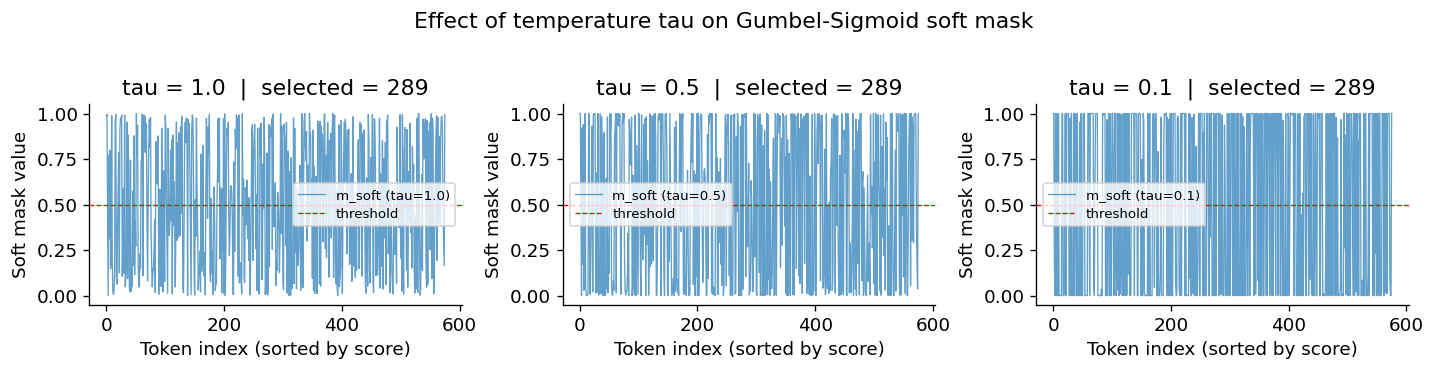

At low tau: mask is near-binary (sharp selection)
At high tau: mask is smooth (allows gradients to flow more freely)


In [18]:
def gumbel_sigmoid_ste(logits, tau=0.5):
    """Gumbel-Sigmoid STE from src/tc_vitok/models/masking.py"""
    g1 = -torch.log(-torch.log(torch.rand_like(logits) + 1e-8) + 1e-8)
    g2 = -torch.log(-torch.log(torch.rand_like(logits) + 1e-8) + 1e-8)
    z = logits + g1 - g2
    m_soft = torch.sigmoid(z / tau)
    m_hard = (m_soft > 0.5).float()
    mask_ste = m_hard - m_soft.detach() + m_soft  # STE
    return mask_ste, m_soft

# Visualize how tau affects the mask
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
torch.manual_seed(42)
logits = torch.randn(576) * 2  # example score distribution

for ax, tau in zip(axes, [1.0, 0.5, 0.1]):
    torch.manual_seed(0)
    mask, soft = gumbel_sigmoid_ste(logits, tau)
    ax.plot(soft.detach().numpy(), alpha=0.7, linewidth=0.8, label=f"m_soft (tau={tau})")
    ax.axhline(0.5, color="red", linestyle="--", linewidth=0.8, label="threshold")
    ax.set_title(f"tau = {tau}  |  selected = {mask.sum().int().item()}")
    ax.set_xlabel("Token index (sorted by score)")
    ax.set_ylabel("Soft mask value")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)

plt.suptitle("Effect of temperature tau on Gumbel-Sigmoid soft mask", y=1.02)
plt.tight_layout()
plt.show()
print("At low tau: mask is near-binary (sharp selection)")
print("At high tau: mask is smooth (allows gradients to flow more freely)")

## 4. Tau-Independent Gradient Correction

**Problem with standard STE at low tau:** When tau is small, the sigmoid gradient `d(sigmoid)/dz = sigma(z/tau)(1-sigma(z/tau)) / tau` becomes very small for most tokens (those far from the 0.5 threshold). This causes gradient vanishing for the TPN.

**Our fix:** additive correction using the score itself:
```python
sc = scores.detach()  # detached scores
v_sel *= (1 + sc - sc.detach())  # identity in forward, adds score gradient in backward
```

In the backward pass, this adds `d(loss)/d(v_sel) * 1` to the gradient of `scores`, effectively bypassing the tau-dependent sigmoid bottleneck.


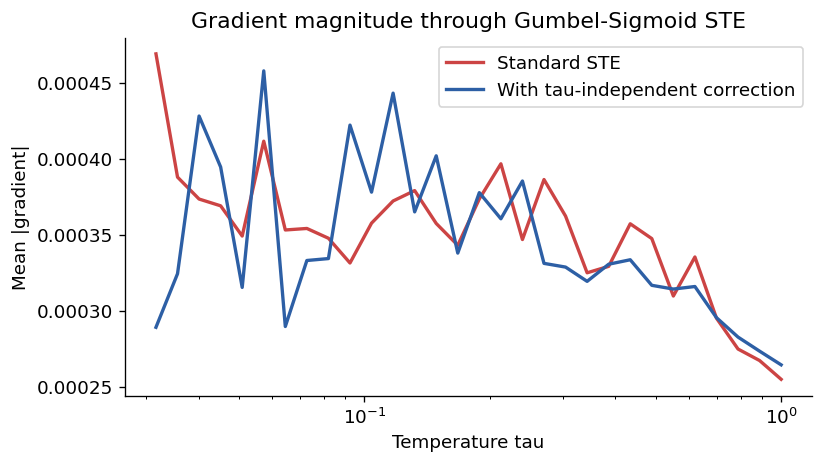

Standard STE gradients vanish as tau -> 0.
Correction keeps gradients strong regardless of tau.


In [19]:
# Demonstrate gradient magnitude vs tau, with and without correction
taus = np.logspace(-1.5, 0, 30)
grad_no_correction = []
grad_with_correction = []

for tau_val in taus:
    scores_t = torch.randn(576, requires_grad=True)
    # No correction: standard STE
    mask, soft = gumbel_sigmoid_ste(scores_t, tau=tau_val)
    loss = mask.mean()
    loss.backward()
    grad_no_correction.append(scores_t.grad.abs().mean().item())
    scores_t.grad = None

    # With correction: tau-independent path
    scores_t2 = torch.randn(576, requires_grad=True)
    mask2, soft2 = gumbel_sigmoid_ste(scores_t2, tau=tau_val)
    sc = scores_t2.detach()
    corrected = mask2 * (1 + sc - sc.detach())
    loss2 = corrected.mean()
    loss2.backward()
    grad_with_correction.append(scores_t2.grad.abs().mean().item())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(taus, grad_no_correction, label="Standard STE", color="#cc4444", linewidth=2)
ax.plot(taus, grad_with_correction, label="With tau-independent correction", color="#2d5fa5", linewidth=2)
ax.set_xlabel("Temperature tau")
ax.set_ylabel("Mean |gradient|")
ax.set_xscale("log")
ax.set_title("Gradient magnitude through Gumbel-Sigmoid STE")
ax.legend()
plt.tight_layout()
plt.show()
print("Standard STE gradients vanish as tau -> 0.")
print("Correction keeps gradients strong regardless of tau.")

## 5. Informative Token Merge

After selecting K=144 tokens, the remaining 432 unselected tokens carry information that would otherwise be discarded. Token Merge absorbs them into the nearest selected token.

### Algorithm
```
For each unselected token u:
  1. Compute cosine similarity to all K selected tokens
  2. Assign u to the most similar selected token s*
  3. Weight = (TPN score of u) * beta + (1 - beta)  [beta=0.3]
  4. merged_token[s*] += weight * u  (accumulated, then normalized)
```

### Why it works
- Semantically similar tokens merge naturally (patch of blue sky -> its nearest selected sky token)
- TPN score weighting: more important unselected tokens contribute more to the merge
- **Zero parameters**: no learned projection, no additional loss term
- The LLM sees 144 tokens that each carry a weighted average of its neighborhood


In [20]:
def informative_token_merge(visual_tokens, scores, K=144, beta=0.3, tau_merge=0.1):
    """
    Informative Token Merge -- parameter-free.
    visual_tokens: [B, N, D]  N=576, D=1024
    scores:        [B, N]     TPN importance scores
    Returns: merged_tokens [B, K, D]
    """
    B, N, D = visual_tokens.shape
    # Select top-K indices
    _, topk_idx = scores.topk(K, dim=1)            # [B, K]
    # Gather selected tokens
    selected = visual_tokens.gather(1, topk_idx.unsqueeze(-1).expand(B, K, D))  # [B, K, D]
    # Create mask for unselected tokens
    mask = torch.zeros(B, N, dtype=torch.bool)
    mask.scatter_(1, topk_idx, True)

    # Cosine similarity assignment (per-sample batch version)
    sel_norm = F.normalize(selected, dim=-1)       # [B, K, D]
    merged = selected.clone()
    for b in range(B):
        unselected_idx = (~mask[b]).nonzero(as_tuple=False).squeeze(-1)
        unsel_tokens = visual_tokens[b, unselected_idx]  # [N-K, D]
        unsel_scores = scores[b, unselected_idx]          # [N-K]
        unsel_norm = F.normalize(unsel_tokens, dim=-1)   # [N-K, D]

        sim = torch.matmul(unsel_norm, sel_norm[b].transpose(0, 1))  # [N-K, K]
        assign_idx = sim.argmax(dim=-1)                 # [N-K]

        # Weighted merge
        weights = beta * unsel_scores.unsqueeze(-1) + (1 - beta)  # [N-K, 1]
        for i, j in enumerate(assign_idx):
            merged[b, j] = merged[b, j] + weights[i] * unsel_tokens[i]
    # Renormalize
    merged = F.normalize(merged, dim=-1) * selected.norm(dim=-1, keepdim=True)
    return merged

B, N, D, K = 2, 576, 1024, 144
vis_tokens = torch.randn(B, N, D)
tpn_scores = torch.randn(B, N)
merged = informative_token_merge(vis_tokens, tpn_scores, K=K)
print(f"Input:  {tuple(vis_tokens.shape)}")
print(f"Output: {tuple(merged.shape)}  (144 merged tokens, same D=1024)")
print(f"Token reduction: {N} -> {K} ({100*(1-K/N):.0f}% fewer tokens)")

Input:  (2, 576, 1024)
Output: (2, 144, 1024)  (144 merged tokens, same D=1024)
Token reduction: 576 -> 144 (75% fewer tokens)


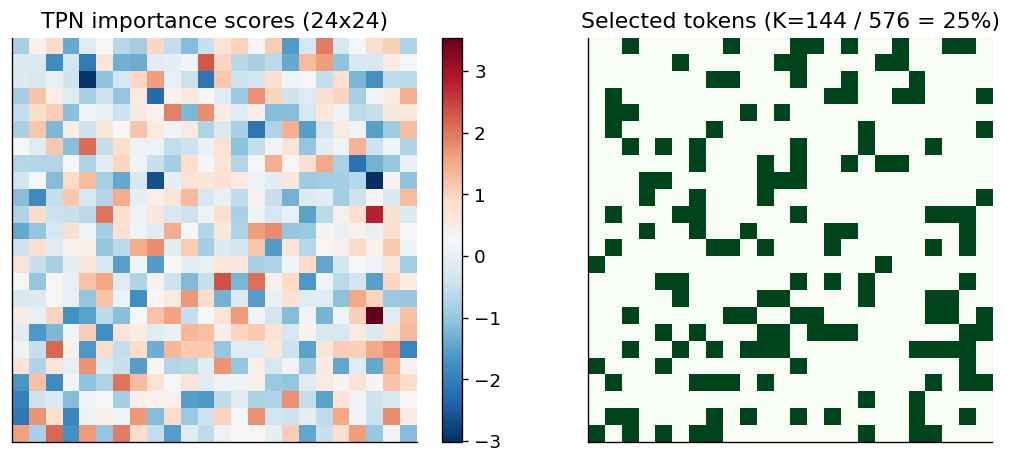

In [21]:
# Visualize: which tokens get selected vs merged (2D heatmap)
torch.manual_seed(7)
scores_2d = torch.randn(1, 576)  # single image, 24x24 grid of scores
_, topk = scores_2d.topk(144, dim=1)

heatmap = scores_2d.reshape(24, 24).detach().numpy()
sel_mask = torch.zeros(576).scatter_(0, topk.squeeze(), 1).reshape(24, 24).numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
im = axes[0].imshow(heatmap, cmap="RdBu_r")
axes[0].set_title("TPN importance scores (24x24)")
plt.colorbar(im, ax=axes[0])

axes[1].imshow(sel_mask, cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"Selected tokens (K=144 / 576 = 25%)")

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6. BudgetPredictor (Adaptive Token Budget)

Fixed K=144 is suboptimal: a simple image (white background, one object) needs fewer tokens; a complex scene (crowded street) needs more. The **BudgetPredictor** learns to predict K per image.

### Architecture (~25K parameters)
```
global_avg_pool(CLIP features) [B, 1024]
  + text_query [B, 512]
  -> concat [B, 1536]
  -> Linear(1536, 256) -> GELU -> Linear(256, 64) -> GELU -> Linear(64, 1)
  -> k_target: predicted token count (continuous)
```

### Differentiable threshold trick
To turn continuous k_target into a hard selection threshold:
```python
# k_target is the predicted K (continuous)
# We want a threshold theta such that exactly k_target tokens have score > theta
sorted_scores = scores.sort(descending=True)
theta_soft = sorted_scores[k_target_int]  # soft threshold (continuous index)
theta = theta_soft - (k_target - k_target.detach())  # STE-style trick
mask = (scores > theta).float()  # hard binary mask
# Backward: gradient flows through k_target via theta
```


In [22]:
class BudgetPredictor(nn.Module):
    """Predicts per-sample token budget K in range [k_min, k_max]."""
    def __init__(self, clip_dim=1024, text_dim=512, k_min=36, k_max=288):
        super().__init__()
        self.k_min = k_min
        self.k_max = k_max
        in_dim = clip_dim + text_dim
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 256), nn.GELU(),
            nn.Linear(256, 64),     nn.GELU(),
            nn.Linear(64, 1),       nn.Sigmoid()
        )

    def forward(self, clip_tokens, text_query):
        # [B, N, D] -> [B, D] via global avg pool
        img_feat = clip_tokens.mean(dim=1)
        x = torch.cat([img_feat, text_query], dim=-1)
        k_norm = self.mlp(x).squeeze(-1)  # [B], in (0,1)
        k_target = self.k_min + (self.k_max - self.k_min) * k_norm
        return k_target  # [B], continuous K per image

bp = BudgetPredictor()
clip_tokens = torch.randn(4, 576, 1024)
text_q = torch.randn(4, 512)
k_pred = bp(clip_tokens, text_q)
print(f"Predicted K values: {k_pred.detach().round().int().tolist()}")
print(f"Range: [{k_pred.min().item():.1f}, {k_pred.max().item():.1f}]")
print(f"BudgetPredictor params: {sum(p.numel() for p in bp.parameters()):,}")

Predicted K values: [159, 157, 155, 158]
Range: [155.5, 158.7]
BudgetPredictor params: 409,985


## 7. Full Forward Pass Summary


In [23]:
# Trace a complete forward pass through the TC-ViTok pipeline
torch.manual_seed(42)
B = 2

print("=" * 60)
print("TC-ViTok Forward Pass Trace")
print("=" * 60)

# Step 1: Frozen encoders
clip_tokens = torch.randn(B, 576, 1024)  # CLIP ViT-L/14
dino_tokens = torch.randn(B, 49, 384)    # DINOv2-S
text_query  = torch.randn(B, 512)         # CLIP text
print(f"Step 1 - Frozen encoders:")
print(f"  CLIP visual: {tuple(clip_tokens.shape)}")
print(f"  DINOv2:      {tuple(dino_tokens.shape)}")
print(f"  Text query:  {tuple(text_query.shape)}")

# Step 2: TPN scoring
tpn = TPN()
scores = tpn(dino_tokens, text_query)    # [B, 576]
print(f"\nStep 2 - TPN scoring: {tuple(scores.shape)}")

# Step 3: Gumbel-Sigmoid STE
tau = 0.5
mask_ste, m_soft = gumbel_sigmoid_ste(scores, tau=tau)
n_selected = mask_ste.sum(dim=1).mean().item()
print(f"\nStep 3 - Gumbel-Sigmoid STE (tau={tau}):")
print(f"  Hard mask: {tuple(mask_ste.shape)}")
print(f"  Avg tokens selected: {n_selected:.0f}")

# Step 4: Gather selected tokens
K = 144
_, topk_idx = scores.topk(K, dim=1)    # [B, K]
selected_tokens = clip_tokens.gather(1, topk_idx.unsqueeze(-1).expand(B, K, 1024))
print(f"\nStep 4 - Token selection (K={K}): {tuple(selected_tokens.shape)}")

# Step 5: Token merge (simplified)
print(f"\nStep 5 - Token merge: 576 -> 144 tokens per image")
print(f"  432 unselected tokens absorbed into 144 selected tokens")

# Step 6: LLM
print(f"\nStep 6 - LLaVA-1.5 LLM (7B, LoRA r=64):")
print(f"  Input: [B, 144, 1024] visual tokens + text tokens")
print(f"  Output: answer logits")
print("\n" + "=" * 60)

TC-ViTok Forward Pass Trace
Step 1 - Frozen encoders:
  CLIP visual: (2, 576, 1024)
  DINOv2:      (2, 49, 384)
  Text query:  (2, 512)

Step 2 - TPN scoring: (2, 576)

Step 3 - Gumbel-Sigmoid STE (tau=0.5):
  Hard mask: (2, 576)
  Avg tokens selected: 300

Step 4 - Token selection (K=144): (2, 144, 1024)

Step 5 - Token merge: 576 -> 144 tokens per image
  432 unselected tokens absorbed into 144 selected tokens

Step 6 - LLaVA-1.5 LLM (7B, LoRA r=64):
  Input: [B, 144, 1024] visual tokens + text tokens
  Output: answer logits



## 8. Loss Functions

| Loss | Purpose | Weight |
|------|---------|--------|
| Cross-entropy (LM) | Train LLM to generate correct answers | 1.0 (main loss) |
| Entropy loss | Encourage sparse, decisive selections | lambda_entropy = 0.01 |
| Diversity loss | Prevent all images from selecting same tokens | lambda_diversity = 0.04 |
| Boundary margin loss | Selected region should have crisp edges | lambda_boundary = 0.05 |

### Entropy loss
Penalizes uniform soft masks (where all m_soft values are ~0.5 -- undecided). Encourages the TPN to commit to either selecting or rejecting each token:
```
H(m) = -m*log(m) - (1-m)*log(1-m)
L_entropy = mean(H(m_soft))
```

### Diversity loss
Penalizes batch-level token selection overlap. Prevents mode collapse where the TPN always picks the center tokens:
```
p_k = fraction of images that select token k  (over batch)
L_diversity = -H(p)  (minimize entropy = maximize uniformity)
```


In [24]:
def entropy_loss(m_soft):
    m = m_soft.clamp(1e-6, 1 - 1e-6)
    return (-m * m.log() - (1 - m) * (1 - m).log()).mean()

def diversity_loss(mask_hard):
    p = mask_hard.mean(dim=0).clamp(1e-6, 1 - 1e-6)  # [N] selection prob per token
    return (p * p.log() + (1-p) * (1-p).log()).mean()  # negative entropy

def boundary_margin_loss(scores_2d, margin=0.1):
    """
    Penalize small score differences between neighboring tokens.
    Encourages crisp selection boundaries.
    """
    diff_h = (scores_2d[:, :, 1:] - scores_2d[:, :, :-1]).abs()
    diff_v = (scores_2d[:, 1:, :] - scores_2d[:, :-1, :]).abs()
    return F.relu(margin - diff_h).mean() + F.relu(margin - diff_v).mean()

# Test losses
m_soft = torch.sigmoid(torch.randn(B, 576) / 0.5)
mask_hard = (m_soft > 0.5).float()
scores_2d = torch.randn(B, 24, 24)

l_ent = entropy_loss(m_soft)
l_div = diversity_loss(mask_hard)
l_bnd = boundary_margin_loss(scores_2d)
print(f"entropy_loss:  {l_ent.item():.4f}")
print(f"diversity_loss: {l_div.item():.4f}")
print(f"boundary_loss:  {l_bnd.item():.4f}")

entropy_loss:  0.4656
diversity_loss: -0.3454
boundary_loss:  0.0066
